# Encontro 9 — Um modelo LUCC com o DisSLUCC

**Modelagem Dinâmica Espacial · LambdaGeo/UFMA**

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lambdageo-edu/curso-modelagem-dinamica-espacial/blob/main/docs/notebooks/encontro09_disslucc.ipynb)

Sem Python instalado? O selo acima abre este notebook no Google Colab, no navegador. Lá, use *Arquivo → Salvar uma cópia no Drive* antes de mudar qualquer coisa: sem a cópia, o que você escrever se perde ao fechar a página.

No encontro 8 vimos a estrutura de um modelo de mudança de uso: **demanda** (quanto), **potencial** (onde é mais provável) e **alocação** (onde de fato muda). Hoje rodamos um modelo de verdade com essa estrutura, com dados prontos: o **lab01** do LuccME, o primeiro exemplo do pacote do INPE, sobre o estado do Acre.

O roteiro da aula:

1. conhecer os dados e as três peças do modelo;
2. rodar o modelo no DisSLUCC;
3. **verificar**: o DisSLUCC dá o mesmo resultado que o LuccME?
4. perguntar se a demanda foi atendida, e descobrir o papel da tolerância;
5. comparar dois **cenários** de demanda: tendência e governança.

🔧 = troque um valor e rode de novo; ✏️ = responda.

## 0. Preparação

No Colab, a célula abaixo instala o DisSModel e o DisSLUCC (cerca de 1 minuto). No laboratório o ambiente já está instalado e ela não instala nada.

In [1]:
import sys
if "google.colab" in sys.modules:
    %pip install -q "dissmodel==0.6.6" "disslucc==0.5.0"

import contextlib, hashlib, io, time, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from dissmodel.core import Environment, Model
from dissmodel.geo.raster.backend import RasterBackend
from disslucc import (AllocationClueLike, AllocationSpec, DemandPreComputedValues,
                      PotentialLinearRegression, RegressionSpec)

Os dados e as saídas do TerraME vêm do repositório `luccme-goldens`, na versão 1.1.0 (DOI 10.5281/zenodo.23161342). A função abaixo baixa cada arquivo e confere o **hash** (encontro 4): se o arquivo não for exatamente o publicado, ela para.

In [2]:
GOLDENS = "https://raw.githubusercontent.com/LambdaGeo/luccme-goldens/v1.1.0/"
ARQUIVOS = {   # caminho no repositório: SHA-256 publicado
    "sources/labs/data/csAC.shp": "c43ca9d839bb3e7b7c503b7e85212ab5a828f6e1710d57297dbf23afa4cbb2b1",
    "sources/labs/data/csAC.dbf": "7992ebdc67fd66a59917c26a685a36448bf9c5dc4b885bbb8c9ce5e2d55b9f8e",
    "sources/labs/data/csAC.shx": "2eba45b6f20dd3eec8a7e9d401e21a14a0ab49d93edd280af485a58b2426fc98",
    "sources/labs/data/csAC.prj": "e908f36376343a9fc35faf56c02ce51c3c9d59b154f617f38992c092f2ee03e9",
    "sources/labs/data/csAC.cpg": "6725e7bbcd28f3a8a586fa34bf191fd72dde8b61756932cd3237c17a6f196f1a",
    "goldens/labs_per_year/lab01/lab01.csv.gz": "35a3bbfc7b66a13cc3ada0cb78c3a989511dbaa317d01de72d230deff9637497",
    "goldens/labs_per_year/lab01_md1643/lab01_md1643.csv.gz": "4e8b82226890f95b38e92c00787c84d2ae69313b1c7ca3c760669a0572ecf694",
}

def baixar(caminho, sha256, pasta=Path("dados_lab01"), tentativas=5):
    destino = pasta / Path(caminho).name
    pasta.mkdir(exist_ok=True)
    for _ in range(tentativas):
        if destino.exists() and hashlib.sha256(destino.read_bytes()).hexdigest() == sha256:
            return destino
        try:
            with urllib.request.urlopen(GOLDENS + caminho) as r:
                destino.write_bytes(r.read())
        except Exception:
            time.sleep(2)
    raise RuntimeError(f"{caminho}: o arquivo baixado não confere com o hash publicado")

locais = {Path(c).name: baixar(c, h) for c, h in ARQUIVOS.items()}
print("arquivos conferidos:", ", ".join(locais))

arquivos conferidos: csAC.shp, csAC.dbf, csAC.shx, csAC.prj, csAC.cpg, lab01.csv.gz, lab01_md1643.csv.gz


## 1. Os dados: o Acre em células de 5 km

O lab01 usa um espaço celular do Acre: cada célula tem 5 km × 5 km (25 km²) e guarda a **fração** de cada classe de uso (floresta `f`, desmatado `d`, outros `outros`) em 2008, além das variáveis explicativas.

In [3]:
celulas = gpd.read_file(locais["csAC.shp"])
print(len(celulas), "células;", celulas.crs.name)
celulas[["row", "col", "f", "d", "outros", "rodovias", "assentamen", "uc_us", "uc_pi", "ti", "fertilidad", "dist_riobr"]].head()

6574 células; SAD69 / Brazil Polyconic


,row,col,f,d,outros,rodovias,assentamen,uc_us,uc_pi,ti,fertilidad,dist_riobr
0,57.0,42,0.356830,0.039787,0.603383,166694.5,0.0,0.0,0.0,1.000000,0.0,477878.4
1,58.0,42,0.869856,0.000000,0.130144,171615.8,0.0,0.0,0.0,1.000000,0.0,477696.5
2,59.0,42,0.656642,0.000000,0.343358,176541.5,0.0,0.0,0.0,1.000000,0.0,477566.9
3,60.0,42,0.733333,0.000000,0.266667,181471.2,0.0,0.0,0.0,0.964019,0.0,477489.6
4,61.0,42,0.340852,0.000000,0.659148,186404.7,0.0,0.0,0.0,0.359309,0.0,477464.6


| Coluna | O que é |
|---|---|
| `f`, `d`, `outros` | fração da célula em floresta, desmatado e outros usos (somam 1) |
| `rodovias` | distância à rodovia mais próxima, em metros |
| `assentamen` | fração da célula em assentamentos rurais |
| `uc_us`, `uc_pi` | fração em unidades de conservação de uso sustentável e de proteção integral |
| `ti` | fração em terras indígenas |
| `fertilidad` | fração com solo fértil (pelo nome; os dados não trazem a definição) |
| `dist_riobr` | distância em linha reta até Rio Branco, a capital, em metros (até cerca de 740 km) |

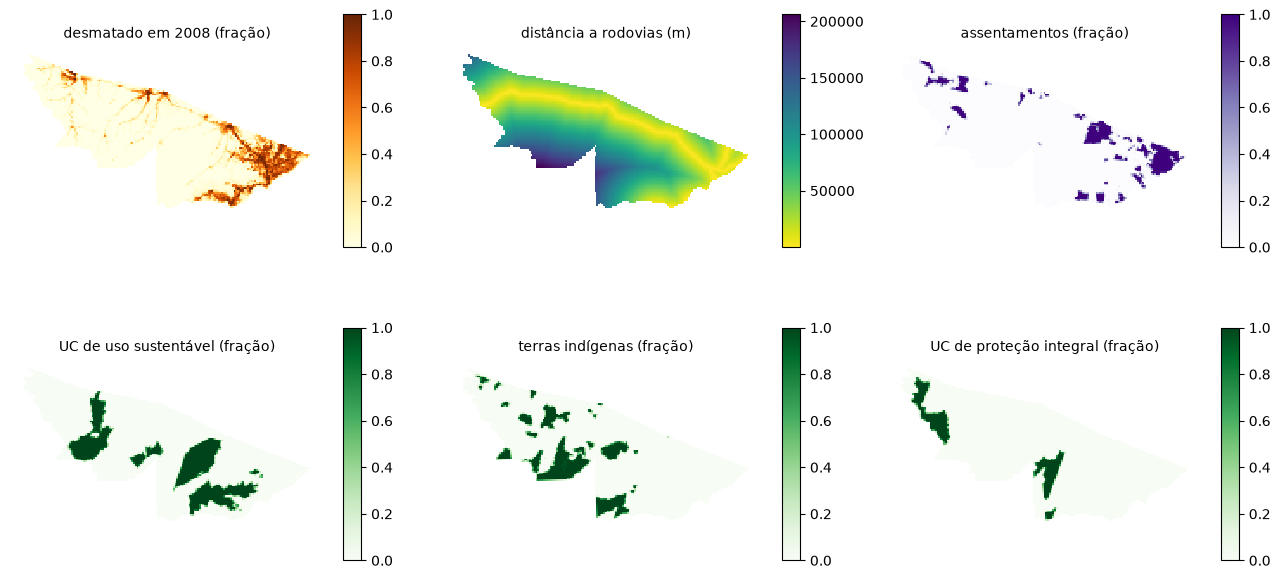

In [4]:
fig, eixos = plt.subplots(2, 3, figsize=(13, 7))
for ax, (col, titulo, cmap) in zip(eixos.flat, [
        ("d", "desmatado em 2008 (fração)", "YlOrBr"), ("rodovias", "distância a rodovias (m)", "viridis_r"),
        ("assentamen", "assentamentos (fração)", "Purples"), ("uc_us", "UC de uso sustentável (fração)", "Greens"),
        ("ti", "terras indígenas (fração)", "Greens"), ("uc_pi", "UC de proteção integral (fração)", "Greens")]):
    celulas.plot(column=col, cmap=cmap, ax=ax, legend=True)
    ax.set_title(titulo, fontsize=10); ax.set_axis_off()
plt.tight_layout()

In [5]:
area = (celulas[["f", "d", "outros"]].sum() * 25).round(0)
print("área em 2008 (km²):"); print(area.to_string())

área em 2008 (km²):
f         137878.0
d          19983.0
outros      6489.0


## 2. Demanda: quanto muda

A demanda é uma tabela com a área de cada classe em cada ano, escrita no script do lab (`DemandPreComputedValues`). Ela não sabe nada do espaço: só diz o total.

In [6]:
ANOS = list(range(2008, 2015))
TENDENCIA = pd.DataFrame([
    [137878.1691, 19982.62882, 6489.202049], [137622.2199, 20238.57805, 6489.202049],
    [137366.2707, 20494.52729, 6489.202049], [137110.3214, 20750.47652, 6489.202049],
    [136824.6853, 21036.11265, 6489.202049], [136539.0492, 21321.74879, 6489.202049],
    [136253.4130, 21607.38493, 6489.202049]], index=ANOS, columns=["f", "d", "outros"])

TENDENCIA["d novo no ano"] = TENDENCIA["d"].diff()
TENDENCIA.round(1)

,f,d,outros,d novo no ano
2008,137878.2,19982.6,6489.2,NaN
2009,137622.2,20238.6,6489.2,255.9
2010,137366.3,20494.5,6489.2,255.9
2011,137110.3,20750.5,6489.2,255.9
2012,136824.7,21036.1,6489.2,285.6
2013,136539.0,21321.7,6489.2,285.6
2014,136253.4,21607.4,6489.2,285.6


Cerca de 256 km² desmatados por ano até 2011 e 286 km² a partir de 2012. A floresta perde exatamente o que o desmatado ganha; `outros` não muda.

## 3. Potencial: onde é mais provável

O potencial de cada classe numa célula vem de uma **regressão linear** sobre as variáveis explicativas, ajustada pelos autores do lab com dados do passado. Os coeficientes também estão no script:

In [7]:
POTENCIAL_F = RegressionSpec(const=0.7392, betas={
    "assentamen": -0.2193, "uc_us": 0.1754, "uc_pi": 0.09708, "ti": 0.1207,
    "dist_riobr": 0.0000002388, "fertilidad": -0.1313})
POTENCIAL_D = RegressionSpec(const=0.267, betas={
    "rodovias": -0.0000009922, "assentamen": 0.2294, "uc_us": -0.09867,
    "dist_riobr": -0.0000003216, "fertilidad": 0.1281})
POTENCIAL_OUTROS = RegressionSpec(const=0.0)    # outros não muda

pd.DataFrame({"floresta (f)": POTENCIAL_F.betas, "desmatado (d)": POTENCIAL_D.betas})

,floresta (f),desmatado (d)
assentamen,-2.193000e-01,2.294000e-01
uc_us,1.754000e-01,-9.867000e-02
uc_pi,9.708000e-02,NaN
ti,1.207000e-01,NaN
dist_riobr,2.388000e-07,-3.216000e-07
fertilidad,-1.313000e-01,1.281000e-01
rodovias,NaN,-9.922000e-07


✏️ **Pergunta 1.** Leia os sinais. Por que o coeficiente de `rodovias` é negativo para o desmatado? E por que `assentamen` é negativo para a floresta e positivo para o desmatado? Algum sinal surpreende?

(Os coeficientes de distância parecem minúsculos porque a distância está em metros: −0,0000009922 por metro é −0,099 a cada 100 km.)

## 4. O modelo completo, no DisSLUCC

A função abaixo junta as três peças: põe as colunas da tabela numa grade (`RasterBackend`), cria a demanda, o potencial e a alocação (`AllocationClueLike`, a mesma do LuccME) e roda os anos. Ela devolve o mapa de cada ano. Não precisa mudar nada nela; repare nos dois parâmetros que vamos variar: a **demanda** e a **tolerância** (`max_difference`).

In [8]:
USOS = ["f", "d", "outros"]
VARIAVEIS = ["assentamen", "uc_us", "uc_pi", "ti", "dist_riobr", "fertilidad", "rodovias"]
linhas, colunas = celulas["row"].astype(int).values, celulas["col"].astype(int).values
FORMA = (linhas.max() + 1, colunas.max() + 1)


def simular(demanda, max_difference, correcao_celula=False):
    """Roda o lab01 e devolve (mapas por ano, iterações da alocação por ano)."""
    grade = RasterBackend(shape=FORMA)
    mascara = np.zeros(FORMA, dtype=np.float32); mascara[linhas, colunas] = 1
    grade.set("mask", mascara)                       # só as células do Acre participam
    for c in USOS + VARIAVEIS:
        a = np.zeros(FORMA, dtype=np.float32); a[linhas, colunas] = celulas[c].astype(float).values
        grade.set(c, a)

    env = Environment(end_time=len(demanda) - 1)     # um passo por ano da tabela
    dem = DemandPreComputedValues(annual_demand=demanda[USOS].values.tolist(), land_use_types=USOS)
    pot = PotentialLinearRegression(backend=grade, demand=dem, land_use_types=USOS, land_use_no_data="outros",
                                    potential_data=[[POTENCIAL_F, POTENCIAL_D, POTENCIAL_OUTROS]])
    alo = AllocationClueLike(
        backend=grade, demand=dem, potential=pot, land_use_types=USOS,
        static={"f": -1, "d": -1, "outros": 1}, complementar_lu="f", cell_area=25.0,
        allocation_data=[AllocationSpec(static=-1, min_value=0, max_value=1, min_change=0, max_change=1),
                         AllocationSpec(static=-1, min_value=0, max_value=1, min_change=0, max_change=1),
                         AllocationSpec(static=1, min_value=0, max_value=1, min_change=0, max_change=1)],
        max_difference=max_difference, cell_correction=correcao_celula)

    mapas = []
    class Fotografo(Model):                          # guarda o mapa ao fim de cada ano
        def execute(self):
            mapas.append({c: np.asarray(grade.get(c), dtype=np.float64)[linhas, colunas].copy()
                          for c in ["f", "d", "outros", "d_pot"]})
    Fotografo()
    with contextlib.redirect_stdout(io.StringIO()):
        env.run()
    return dict(zip(ANOS, mapas)), list(alo.iterations_per_step)

Rodamos com os parâmetros do lab original: a demanda de tendência e tolerância de 5.000 km².

In [9]:
inicio = time.perf_counter()
original, iteracoes = simular(TENDENCIA, max_difference=5000)
print(f"rodou em {time.perf_counter() - inicio:.2f} s; iterações da alocação por ano: {iteracoes}")

rodou em 0.01 s; iterações da alocação por ano: [0, 0, 0, 0, 0, 0, 0]


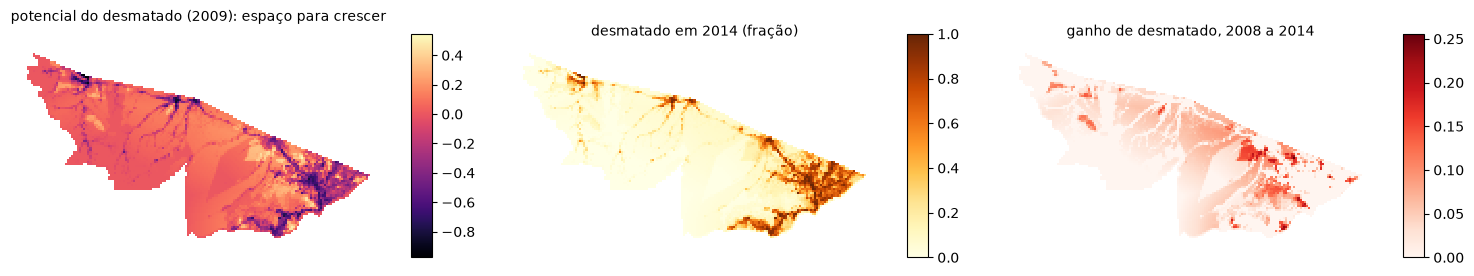

In [10]:
def mapa(valores, titulo, ax, **kw):
    celulas.assign(v=valores).plot(column="v", ax=ax, legend=True, **kw)
    ax.set_title(titulo, fontsize=10); ax.set_axis_off()

fig, eixos = plt.subplots(1, 3, figsize=(15, 4.5))
mapa(original[2009]["d_pot"], "potencial do desmatado (2009): espaço para crescer", eixos[0], cmap="magma")
mapa(original[2014]["d"], "desmatado em 2014 (fração)", eixos[1], cmap="YlOrBr", vmin=0, vmax=1)
mapa(original[2014]["d"] - original[2008]["d"], "ganho de desmatado, 2008 a 2014", eixos[2], cmap="Reds", vmin=0)
plt.tight_layout()

Um detalhe no primeiro mapa: o potencial que a alocação usa é a regressão **menos a fração que a célula já tem** (como no LuccME). Por isso ele é negativo onde já está quase tudo desmatado, ao longo das estradas: ali não há mais espaço para crescer.

✏️ **Pergunta 2.** Onde o desmatamento avança? Compare o terceiro mapa com os mapas de rodovias e assentamentos da Parte 1.

## 5. Verificação: é o mesmo resultado do LuccME?

O `luccme-goldens` guarda o que o TerraME/LuccME calculou para o lab01, célula a célula e ano a ano. Comparamos com o DisSLUCC, casando as células pela linha e coluna:

In [11]:
def comparar(mapas, arquivo_golden):
    golden = pd.read_csv(arquivo_golden).set_index(["year", "row", "col"])
    indice = pd.MultiIndex.from_arrays([linhas, colunas], names=["row", "col"])
    linhas_tabela = []
    for ano in ANOS:
        ref = golden.loc[ano].reindex(indice)
        linhas_tabela.append({"ano": ano,
                              "maior diferença em f": np.abs(mapas[ano]["f"] - ref["f_out"].values).max(),
                              "maior diferença em d": np.abs(mapas[ano]["d"] - ref["d_out"].values).max()})
    return pd.DataFrame(linhas_tabela).set_index("ano")

comparar(original, locais["lab01.csv.gz"])

,maior diferença em f,maior diferença em d
ano,,
2008,4.500000e-07,2.974091e-08
2009,4.250000e-07,4.136128e-08
2010,4.250000e-07,4.989857e-08
2011,4.250000e-07,4.406731e-08
2012,4.250000e-07,5.749405e-08
2013,4.250000e-07,4.923155e-08
2014,4.250000e-07,6.182019e-08


Diferenças da ordem de 10⁻⁷: o ruído do formato numérico (`float32`) usado na grade. Os dois programas fazem as mesmas contas.

O lab01 original quase não testa o laço de ajuste da alocação: com tolerância de 5.000 km², ele aceita a primeira tentativa todo ano (0 iterações). O `luccme-goldens` tem uma variante com tolerância de 1.643 km², em que o laço roda de verdade:

In [12]:
variante, iter_variante = simular(TENDENCIA, max_difference=1643)
print("iterações no DisSLUCC:", iter_variante)
print("iterações no TerraME:  [0, 0, 8, 26, 18, 17, 17]   (terrame.log do golden)")
comparar(variante, locais["lab01_md1643.csv.gz"]).max().to_frame("maior diferença, todos os anos")

iterações no DisSLUCC: [0, 0, 8, 26, 18, 17, 17]
iterações no TerraME:  [0, 0, 8, 26, 18, 17, 17]   (terrame.log do golden)


,"maior diferença, todos os anos"
maior diferença em f,4.500000e-07
maior diferença em d,9.565841e-08


Mesmo número de iterações em todos os anos e diferenças na sétima casa decimal.

Há um ponto em que o DisSLUCC **difere de propósito**. No LuccME, uma correção de célula prevista no algoritmo nunca é executada, por causa de um erro de digitação no código Lua (um campo com nome errado). O DisSLUCC executa a correção por padrão; o parâmetro `correcao_celula=False` usado até aqui reproduz o LuccME. Com a correção:

In [13]:
corrigido, _ = simular(TENDENCIA, max_difference=5000, correcao_celula=True)
print(f"maior diferença em d (2014), com e sem a correção: {np.abs(corrigido[2014]['d'] - original[2014]['d']).max():.3f}")

maior diferença em d (2014), com e sem a correção: 0.039


Uma diferença de até 4 pontos percentuais numa célula, documentada no `disslucc-benchmark`. Verificar não é só achar igualdade: é saber **onde** e **por que** dois programas diferem.

## 6. A demanda foi atendida?

O modelo bate com o LuccME. Mas ele faz o que a demanda pede? Somamos a área desmatada do mapa simulado em cada ano:

In [14]:
def area_simulada(mapas, uso="d"):
    return pd.Series({ano: (m[uso] * 25).sum() for ano, m in mapas.items()})

conferencia = pd.DataFrame({"demanda (km²)": TENDENCIA["d"],
                            "simulado, tolerância 5000": area_simulada(original),
                            "simulado, tolerância 1643": area_simulada(variante)}).round(0)
conferencia["excesso com 5000"] = conferencia["simulado, tolerância 5000"] - conferencia["demanda (km²)"]
conferencia

,demanda (km²),"simulado, tolerância 5000","simulado, tolerância 1643",excesso com 5000
2008,19983.0,19983.0,19983.0,0.0
2009,20239.0,20953.0,20953.0,714.0
2010,20495.0,21827.0,21512.0,1332.0
2011,20750.0,22613.0,21706.0,1863.0
2012,21036.0,23320.0,22006.0,2284.0
2013,21322.0,23957.0,22312.0,2635.0
2014,21607.0,24530.0,22609.0,2923.0


Com a tolerância do lab original, o modelo desmata em 2014 quase 2.900 km² a mais do que a demanda pede: aceita qualquer resultado que fique a menos de 5.000 km² do pedido. O teste de verificação passou, porque o LuccME faz exatamente o mesmo.

✏️ **Pergunta 3.** A verificação deu igualdade com o LuccME e, mesmo assim, o modelo não respeita a demanda. Isso é uma contradição? O que a verificação garante, e o que ela não garante?

Para os cenários usamos tolerância de 200 km² (menos de 1% da área desmatada), que obriga a alocação a iterar até chegar perto da demanda.

In [15]:
TOLERANCIA = 200    # km²; 🔧 experimente 1000 ou 50

inicio = time.perf_counter()
tendencia, iter_tend = simular(TENDENCIA, max_difference=TOLERANCIA)
print(f"rodou em {time.perf_counter() - inicio:.1f} s; iterações por ano: {iter_tend}")
print(f"desmatado em 2014: simulado {area_simulada(tendencia)[2014]:,.0f} km², demanda {TENDENCIA['d'][2014]:,.0f} km²")

rodou em 0.8 s; iterações por ano: [0, 333, 332, 329, 309, 305, 302]
desmatado em 2014: simulado 21,611 km², demanda 21,607 km²


## 7. Dois cenários: tendência e governança

O cenário de **tendência** é a demanda do lab. No cenário de **governança**, uma política reduz à metade o desmatamento de cada ano. Só a demanda muda: o potencial, a alocação e os dados são os mesmos.

In [16]:
REDUCAO = 0.5    # 🔧 fração do desmatamento anual que a política evita

GOVERNANCA = TENDENCIA.copy()
ganho = (TENDENCIA["d"] - TENDENCIA["d"].iloc[0]) * (1 - REDUCAO)
GOVERNANCA["d"] = TENDENCIA["d"].iloc[0] + ganho
GOVERNANCA["f"] = TENDENCIA["f"].iloc[0] - ganho
GOVERNANCA = GOVERNANCA[USOS]

governanca, iter_gov = simular(GOVERNANCA, max_difference=TOLERANCIA)
print("iterações por ano:", iter_gov)

iterações por ano: [0, 428, 433, 433, 418, 415, 414]


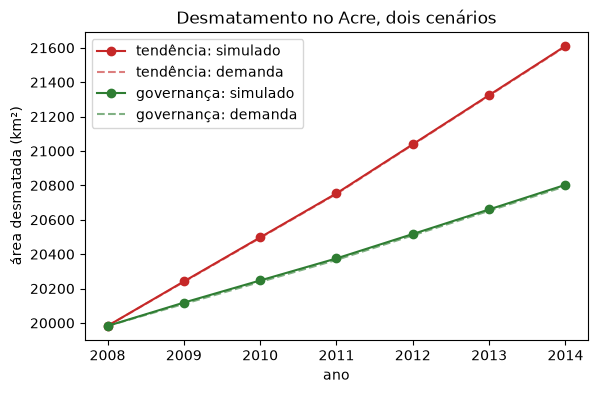

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for nome, mapas, dem, cor in [("tendência", tendencia, TENDENCIA, "#c62828"), ("governança", governanca, GOVERNANCA, "#2e7d32")]:
    ax.plot(ANOS, area_simulada(mapas), "o-", color=cor, label=f"{nome}: simulado")
    ax.plot(ANOS, dem["d"], "--", color=cor, alpha=0.6, label=f"{nome}: demanda")
ax.set(xlabel="ano", ylabel="área desmatada (km²)", title="Desmatamento no Acre, dois cenários"); ax.legend();

As curvas mostram **quanto**. Para saber **onde** os cenários diferem, comparamos os mapas de 2014:

células com mais de 1 ponto percentual de diferença em 2014: 1135 de 6574


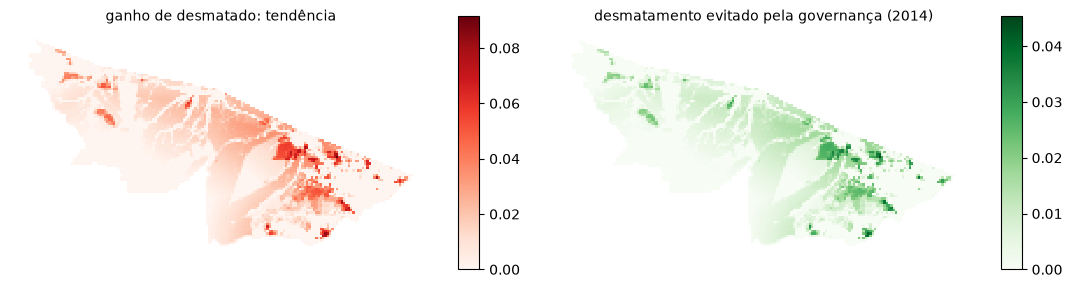

In [18]:
diferenca = tendencia[2014]["d"] - governanca[2014]["d"]
celulas_diferentes = (np.abs(diferenca) > 0.01).sum()
print(f"células com mais de 1 ponto percentual de diferença em 2014: {celulas_diferentes} de {len(celulas)}")

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5))
mapa(tendencia[2014]["d"] - tendencia[2008]["d"], "ganho de desmatado: tendência", eixos[0], cmap="Reds", vmin=0)
mapa(diferenca, "desmatamento evitado pela governança (2014)", eixos[1], cmap="Greens", vmin=0)
plt.tight_layout()

✏️ **Pergunta 4.** Onde está o desmatamento evitado: espalhado pelo estado ou concentrado? Por que ele aparece justamente ali? (Dica: compare com o mapa do potencial.)

## Para casa

1. 🔧 Dobre o coeficiente de `rodovias` no potencial do desmatado (`-0.0000019844`) e rode o cenário de tendência. A área desmatada em 2014 muda? E o mapa? Explique com o encontro 8: a demanda decide quanto, o potencial decide onde.
2. Faça um cenário intermediário (`REDUCAO = 0.25`) e acrescente a curva ao gráfico dos cenários.
3. Volte à ficha de leitura do encontro 8: quais dos drivers do seu projeto aparecem no lab01? Quais faltam, e de onde viriam? Essa lista é o ponto de partida do encontro 10.